In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
file_path = "temp/finalcoincs.bin"
column_names = ["id1", "id2", "x", "y", "z", "dx1", "dy1", "dz1", "dx2", "dy2", "dz2"]
column_types = [np.int16, np.int16, np.float32, np.float32, np.float32, np.float32, np.float32, np.float32, np.float32, np.float32, np.float32]
num_cols = len(column_types)
dtype = np.dtype({'names': column_names, 'formats': column_types})
data = np.fromfile(file_path, dtype=dtype)
print(len(data))
print(data[0:10]) 

4152752
[(4252, 3432,  107.17   ,  -55.5747,  -3.87605, -0.966453,  0.25565  ,  0.0247183 ,  0.966453, -0.25565  , -0.0247183 )
 (3686,   10, -100.896  ,   63.8477, -34.3884 , -0.939189, -0.340233 ,  0.0465312 ,  0.939189,  0.340233 , -0.0465312 )
 (5933, 1868,   24.7728 , -117.71  ,  15.3709 ,  0.975141, -0.221372 ,  0.00966986, -0.975141,  0.221372 , -0.00966986)
 ( 156, 2813,   53.3954 ,  107.291 , -10.9082 ,  0.899306,  0.437221 , -0.00927777, -0.899306, -0.437221 ,  0.00927777)
 (2362, 5733,  105.56   ,   56.3662,  -1.71409,  0.925067, -0.346352 ,  0.155855  , -0.925067,  0.346352 , -0.155855  )
 ( 215, 5052,   -2.13641, -120.562 ,  17.202  ,  0.974679,  0.151896 ,  0.164099  , -0.974679, -0.151896 , -0.164099  )
 ( 781, 5596,  -23.1024 ,  118.098 ,  31.0059 ,  0.996085,  0.0218522, -0.0856582 , -0.996085, -0.0218522,  0.0856582 )
 (5406,  710,   33.0884 , -115.494 ,  11.6842 , -0.993352, -0.0626855, -0.0965571 ,  0.993352,  0.0626855,  0.0965571 )
 (2621,  603,  118.713  ,  -16.8

In [3]:
positions = data[['x', 'y', 'z']]
img = np.zeros((360, 360, 110), dtype=np.int16)
for i in range(len(positions)):
    x, y, z = positions[i]
    x = int(x + 180)
    y = int(y + 180)
    z = int(z + 55)
    img[x, y, z] += 1


0.0


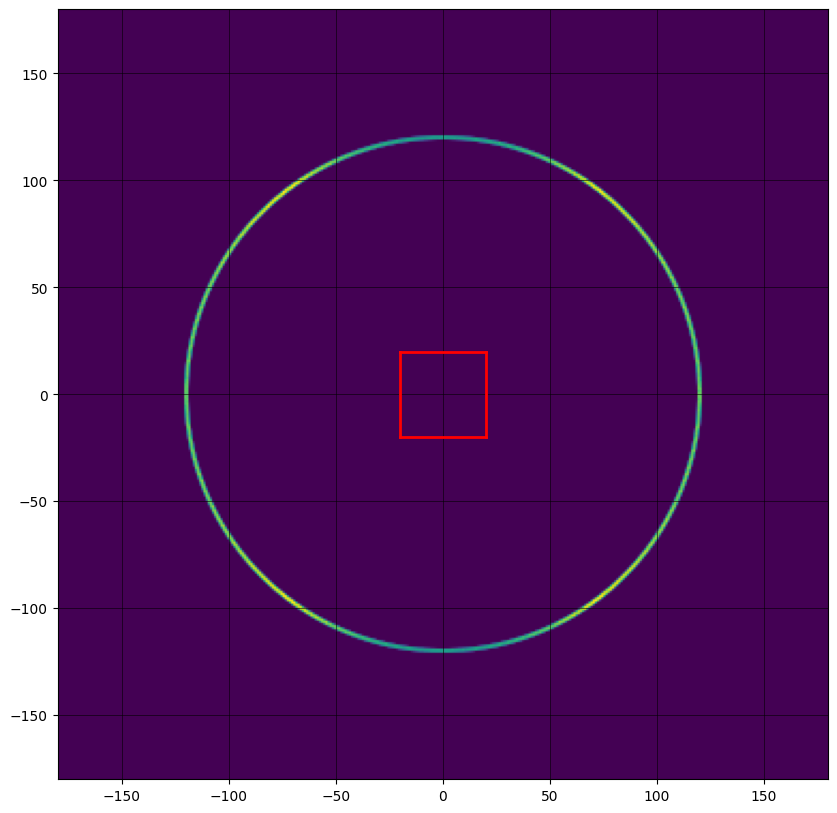

In [4]:
plt.figure(figsize=(10, 10))
#img.tofile("/home/kale-chen/Documents/PET/Sensitivity Normalization/sensimgs/mc3d.bin")
imgxy = np.sum(img, axis = 2).T / np.mean(np.sum(img, axis = 2).T)
#imgxy.tofile("/home/kale-chen/Documents/PET/Sensitivity Normalization/sensimgs/mc.bin")
plt.imshow(imgxy, extent=[-180, 180, -180, 180])
v1, v2 = -20, 20
print(np.sum(imgxy[v1 + 180:v2 + 180, v1 + 180:v2 + 180]))
plt.plot([v1, v2], [v1, v1], 'r-', linewidth=2)
plt.plot([v2, v2], [v1, v2], 'r-', linewidth=2)
plt.plot([v1, v2], [v2, v2], 'r-', linewidth=2)
plt.plot([v1, v1], [v1, v2], 'r-', linewidth=2)
plt.grid(True, color='black', linewidth=0.4)
plt.show()

In [ ]:
ids = data[['id1', 'id2']]
idsarray = np.zeros((len(ids), 2), dtype=np.int16)
for i in range(len(ids)):
    idsarray[i, 0] = ids[i][0]
    idsarray[i, 1] = ids[i][1]
idsarray.tofile("/home/kale-chen/Documents/Geant4/TPPTsim/temp/ids.bin")
print(idsarray[0:10])

[[4252 3432]
 [3686   10]
 [5933 1868]
 [ 156 2813]
 [2362 5733]
 [ 215 5052]
 [ 781 5596]
 [5406  710]
 [2621  603]
 [ 564 4439]]


In [14]:
print(len(np.unique(idsarray)))

6144
